# micrograd 2: manual backprop

Karpathy, *Zero to Hero* #1, from ~0:32 to ~1:09 (stop when he starts writing `_backward`; that's session 3).

Goal: every gradient by hand with the chain rule, each one checked against a numerical estimate.

**Rules:** pause before each step he does and do it first. Type everything. Predict before you run.

## Block 0: carry-over (5 min)
Your `Value`, `trace` and `draw_dot` from session 1, unchanged. Run it: `L` should draw with data -8.0.

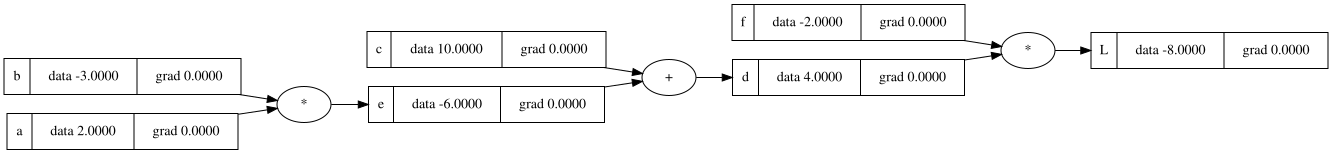

In [1]:
"""Graph drawing for Value. Graphviz boilerplate: read trace() closely, skim the rest."""
from graphviz import Digraph
import math
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0.0

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        return out

    def __radd__(self, other):   # handles other + self
        return self + other

    def __rmul__(self, other):   # handles other * self
        return self * other

    def tanh(self):
        t = math.tanh(self.data)
        out = Value(t, (self,), 'tanh')
        return out
        

a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d * f; L.label = 'L'

# predict:i think it will return Value(data=2.0)



def trace(root):
    # Walk backwards from root through _prev, collecting every node and edge.
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label=f"{{ {n.label} | data {n.data:.4f} | grad {n.grad:.4f} }}", shape='record')
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot



draw_dot(L)

# predict:i think it will return Value(data=-8.0)







## Block 1: give every node a gradient (15 min)
1. Add `self.grad = 0.0` to `__init__`. Why `0.0` rather than `None`? Think about what a node that doesn't affect `L` should report.
2. Show `grad` in the `draw_dot` record label.
3. Predict before running: what is `L.grad`, and why is it the one gradient you know without any calculus?

In [2]:
# predict: L.grad = 
def lol():


    h = 0.0001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d * f; L.label = 'L'
    L1 = L

    
    a = Value(2.0 + h, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d * f; L.label = 'L'
    L2 = L

    return ((L2 - L1) / h)

print(lol())

TypeError: unsupported operand type(s) for -: 'Value' and 'Value'

## Block 2: backprop by hand through L = (a*b + c)*f (35 min)
On paper first. For each node write *local derivative x gradient flowing in*: dL/dL, dL/dd, dL/df, dL/de, dL/dc, dL/da, dL/db.

Then set each `.grad` by hand and redraw.

Checker: write `numgrad`, which rebuilds L with one leaf nudged and returns the **central** difference. You know from session 1 why central, and why not h = 1e-15.

In [30]:
# by hand, before he does it:
# dL/dd = -2
# dL/df = 4
# dL/de = -2
# dL/dc = -2
# dL/da = 6
# dL/db = -4


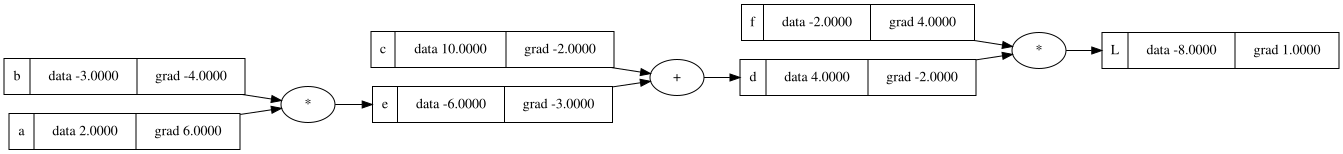

In [2]:
# set the .grad values, then draw_dot(L)
L.grad = 1.0
f.grad = 4.0
d.grad = -2
e.grad = -3
c.grad = -2
a.grad = 6
b.grad = -4
draw_dot(L)

In [12]:
# numgrad: your central-difference checker. Check all six.
def L_of(a, b, c, f):
    e = a*b
    d = e + c
    return d*f

h = 0.001
a0, b0, c0, f0 = 2.0, -3.0, 10.0, -2.0

num_a = (L_of(a0 + h, b0, c0, f0) - L_of(a0 - h, b0, c0, f0)) / (2*h)
print('dL/da', num_a, 'hand:', 6)



a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad
print(a.data)
e = a*b; d = e + c; L = d*f
print(L.data)


dL/da 6.000000000000227 hand: 6
2.06
-7.286496


Write one sentence in your notes: why does a `+` node pass its incoming gradient through unchanged, to both inputs?

## Block 3: one optimisation step (10 min)
Nudge every leaf by `0.01 * leaf.grad` and recompute L.

Predict first: does L go up or down? Then estimate by how much using only the gradients (first-order: dL is about the sum of grad x step). Compare with the real change. Why aren't they exactly equal?

In [ ]:
# predict: L goes ___ by about ___


## Block 4: a neuron (40 min)
`x1 = 2.0, x2 = 0.0, w1 = -3.0, w2 = 1.0, b = 6.8813735870195432`, `n = x1*w1 + x2*w2 + b`, `o = tanh(n)`.

1. Add a `tanh` method to `Value` (one node, one input). Write tanh in terms of exp and derive d tanh/dn **before** he does.
2. Why that oddly precise `b`? Look at `o` and at your derivative.
3. Backprop by hand to x1, x2, w1, w2. Predict which gradients are 0 before you calculate, and say why.
4. `numgrad` every one.

In [6]:
# d/dn tanh(n) = 
import math
n = 5
h = 0.000001 
print(1 - math.tanh(0.5)**2)
print((math.tanh(0.5 + h) - math.tanh(0.5 - h)) / (2*h))
b = 6.8813735870195432
n = 2 * -3 + b
o = math.tanh(n)
t = 1 - o*o
print(t)




x1 = Value(2.0, label='x1'); x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1'); w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')
x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1x2w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
o.grad = 1
n.grad = 0.5
w2.grad = 0
x2.grad = 1 * 0.5
x1.grad = -3 * 0.5
w1.grad = 2 * 0.5
x1w1x2w2.grad = 0.5
x1w1.grad = 0.5
x2w2.grad = 0.5
b.grad = 0.5
draw_dot(o)


import math
def o_of(x1, x2, w1, w2, b=6.8813735870195432):
    return math.tanh(x1*w1 + x2*w2 + b)

h = 0.001
x1_0, x2_0, w1_0, w2_0 = 2.0, 0.0, -3.0, 1.0   # new names, so x1 etc. stay Values

num_x1 = (o_of(x1_0 + h, x2_0, w1_0, w2_0) - o_of(x1_0 - h, x2_0, w1_0, w2_0)) / (2*h)
print('do/dx1', num_x1, 'hand:', -1.5)
num_x2 = (o_of(x1_0, x2_0 + h, w1_0, w2_0) - o_of(x1_0, x2_0 - h, w1_0, w2_0)) / (2*h)
print('do/dx2', num_x2, 'hand:', 0.5)
num_w1 = (o_of(x1_0, x2_0, w1_0 + h, w2_0) - o_of(x1_0, x2_0, w1_0 - h, w2_0)) / (2*h)
print('do/dw1', num_w1, 'hand:', 1.0)
num_w2 = (o_of(x1_0, x2_0, w1_0, w2_0 + h) - o_of(x1_0, x2_0, w1_0, w2_0 - h)) / (2*h)
print('do/dw2', num_w2, 'hand:', 0.0)


0.7864477329659274
0.786447733019946
0.4999999999999998
do/dx1 -1.5000022499858656 hand: -1.5
do/dx2 0.5000000833334517 hand: 0.5
do/dw1 1.0000006666646688 hand: 1.0
do/dw2 0.0 hand: 0.0


In [ ]:
# predict: zero gradients will be ___ because ___


## Reflection (10 min)
Add to `notes/micrograd.md`: **learned / surprised / question it opened**.

CS x Phil: last time you asked whether a gradient is a causal claim. Today dL/da came from chaining local "what if I nudge this" facts. Does chaining local interventions give a global causal claim? Look at w2: it clearly *can* matter to o, yet its gradient is 0 here. What does that say about causal relevance depending on background conditions?

Then: `git add -A && git commit -m "micrograd 2: manual backprop" && git push`